# ITM 454 - Natural Language Processing
## Final Project: Sentiment Analysis of Khmer Customer Reviews — **01. Data Preparation**

---

We build a **Khmer sentiment classifier** for customer reviews of **BookMeBus** (a Cambodian bus, van and ferry booking
platform) and compare three model families in the next notebooks:

| Notebook | Model family | Model |
|---|---|---|
| 02 | Statistical ML | TF-IDF + Logistic Regression |
| 03 | Neural network | BiLSTM with fastText Khmer embeddings |
| 04 | Transformer | fine-tuned XLM-R |

This first notebook prepares the data for all of them:

1. **Dataset** → load our new labels (Part A)
2. **Weak labels vs. new labels** → why we relabeled, and why we use 2 classes
3. **Model input text** → one Khmer text per review
4. **Text preprocessing** → clean the text and cut Khmer into words (khmer-nltk)
5. **Dataset distribution** → how long are the reviews? → `max_len`
6. **Train / validation / test splits**
7. **Gold labels** for the native-Khmer test set
8. **Save** the splits for notebooks 02–05

### 0. Setup

**How to run:** open this notebook from the `notebooks/` folder of the project and run all cells (Kernel → Restart & Run All).
The setup cell below goes to the project folder and installs the packages from `requirements.txt`
(see the README for creating the Python environment). All paths in this notebook are relative to the project folder.

**Before this notebook:** This is the **first** notebook: it needs no earlier notebook.

| Input file | Where it comes from |
|---|---|
| `data/labels/bookmebus_labeled.csv` | Part A labels (`scripts/finalize_labels.py`; already in the repository) |
| `data/labels/gold_test_annotation_A.csv`, `_B.csv`, `gold_disagreements.csv` | gold annotation by two team members (already in the repository) |
| `data/labels/gold_test_labels.csv` | gold labels; created by this notebook from the files above if it does not exist yet |


| Output | Used by |
|---|---|
| `src/preprocess.py` | notebooks 02–03 and the web app |
| `data/processed/train.csv`, `val.csv`, `test_translated.csv`, `test_native.csv`, `settings.json` | notebooks 02–05 |
| `results/figures/01_*.png` | report |

In [1]:
import os

# 1. Go to the project folder (this notebook is in its notebooks/ folder)
PROJECT_DIR = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
os.chdir(PROJECT_DIR)

# 2. Install the packages (the exact versions we used are in requirements.txt)
%pip install -q -r requirements.txt

# 3. Folders for the outputs
for folder in ["data/processed", "results/predictions", "results/metrics", "results/figures", "models", "src"]:
    os.makedirs(folder, exist_ok=True)
print("Project folder:", os.path.basename(os.path.abspath(".")))

Note: you may need to restart the kernel to use updated packages.
Project folder: nlp_project


### 1. Import Required Libraries

In [2]:
import os
import re
import sys
import json
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import cohen_kappa_score

# Seed values for reproducibility (seed 45 everywhere in the project)
SEED = 45
random.seed(SEED)
np.random.seed(SEED)

#### Khmer font for plots

The default matplotlib font has no Khmer letters, so Khmer text would appear as empty boxes □□□.
We use a Khmer font if one is installed (Noto Sans Khmer, Khmer OS or Khmer UI).

In [3]:
from matplotlib import font_manager

installed_fonts = {font.name for font in font_manager.fontManager.ttflist}
khmer_font = next((name for name in ["Noto Sans Khmer", "Khmer OS", "Khmer UI", "DaunPenh"] if name in installed_fonts), None)
if khmer_font:
    plt.rcParams["font.family"] = [khmer_font, "DejaVu Sans"]   # Khmer font first, normal font as backup
print("Khmer font for plots:", khmer_font or "none found (Khmer text may appear as boxes)")

Khmer font for plots: Khmer OS


### 2. Dataset

We load the file from **Part A**: every BookMeBus review with a new sentiment label.

| Column | Meaning |
|---|---|
| `text` | the original review (mostly English, some Khmer) |
| `Translation` | Khmer translation of `text` (already in the dataset) |
| `score` | the 0–5 star rating (only used for the comparison in step 3) |
| `label` | **new** label read from the review text: positive / neutral / negative |
| `exclude` | `yes` = the row cannot be labeled (missing text, only a name, …) |
| `is_original_khmer` | `yes` = the review was written in Khmer |

> The new labels were produced by **Claude (an AI model)** by reading each review, following
> `data/labels/LABELING_GUIDELINES.md`. They are **silver labels**: good, but not checked by humans.

In [4]:
df = pd.read_csv("data/labels/bookmebus_labeled.csv", keep_default_na=False)
df["score"] = df["score"].astype(float)

print("Rows, columns:", df.shape)
df[["row_id", "text", "score", "label", "confidence", "is_original_khmer"]].sample(5, random_state=SEED)

Rows, columns: (4114, 12)


,row_id,text,score,label,confidence,is_original_khmer
246,246,"The bus was 20 minutes late from the schedule,...",4.0,positive,high,no
2750,2750,"Just amazing , everything was perfet",5.0,positive,high,no
2073,2073,Very good service thank you bookmebus,4.2,positive,high,no
2148,2148,"Everything was great - snacks, driver helpfuln...",4.2,negative,medium,no
221,221,"One of, if not the worst, bus ride I’ve ever h...",1.0,negative,high,no


#### Labels per class

Colors used in the whole project: **positive = green**, **neutral = grey**, **negative = red**.

label
negative      1966
positive      1898
neutral        234
(excluded)      16
Name: count, dtype: int64


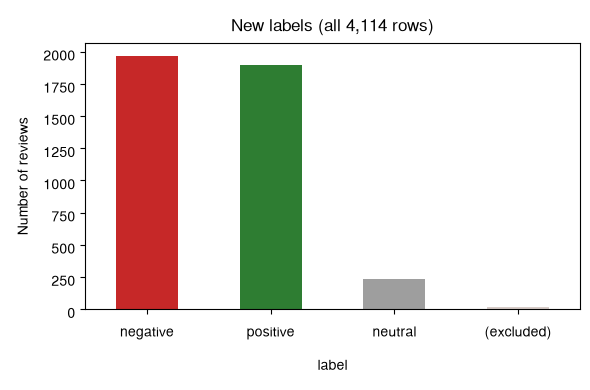

In [5]:
COLORS = {"positive": "#2e7d32", "neutral": "#9e9e9e", "negative": "#c62828", "(excluded)": "#d7ccc8"}

label_counts = df["label"].replace("", "(excluded)").value_counts()
print(label_counts)

label_counts.plot(kind="bar", color=[COLORS[name] for name in label_counts.index], figsize=(6, 4))
plt.title("New labels (all 4,114 rows)")
plt.ylabel("Number of reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("results/figures/01_label_counts.png", dpi=150)
plt.show()

#### Remove the excluded rows

These rows have no usable review text, so they cannot be used for training or testing.

In [6]:
print("Excluded rows:", (df["exclude"] == "yes").sum())
print(df.loc[df["exclude"] == "yes", "exclude_reason"].value_counts().to_string())

df = df[df["exclude"] == "no"].reset_index(drop=True)
print("\nRows left:", len(df))

Excluded rows: 16
exclude_reason
meaningless text                                      10
missing text (Translation is a placeholder 'none')     3
original text corrupted by Excel (#NAME?)              2
number-only text ('250')                               1

Rows left: 4098


### 3. Weak Labels vs. New Labels

In our proposal we planned to use **weak labels** made from the star score:

| Score | Weak label |
|---|---|
| ≤ 2 | negative |
| between 2 and 4 | neutral |
| ≥ 4 | positive |

But a score does not always match what the customer **wrote**. Let's compare the weak labels with our new labels
(which were read from the text).

In [7]:
def score_to_weak_label(score):
    if score <= 2:
        return "negative"
    elif score < 4:
        return "neutral"
    else:
        return "positive"

df["weak_label"] = df["score"].apply(score_to_weak_label)

order = ["negative", "neutral", "positive"]
cross = pd.crosstab(df["weak_label"], df["label"], rownames=["weak label (score)"], colnames=["new label (text)"])
print(cross.reindex(index=order, columns=order))

agreement = (df["weak_label"] == df["label"]).mean()
print(f"\nAgreement between weak labels and new labels: {agreement:.1%}")

new label (text)    negative  neutral  positive
weak label (score)                             
negative                 720       10         4
neutral                 1001      102       163
positive                 245      122      1731

Agreement between weak labels and new labels: 62.3%


#### Examples where the score and the text disagree

In [8]:
examples = pd.concat([
    df[(df["score"] >= 4) & (df["label"] == "negative")].sample(4, random_state=SEED),   # high score, but a complaint
    df[(df["score"] <= 2) & (df["label"] == "positive")].sample(2, random_state=SEED),   # low score, but praise
])
for _, row in examples.iterrows():
    print(f"score {row['score']:.1f} | new label: {row['label']:8s} | {row['text'][:140]}")

score 5.0 | new label: negative | Lower Bed doesn’t have light bulb which makes the room very dark . passenger couldn’t seat only sleep . Air conditioner is remain very  cold
score 4.0 | new label: negative | Salió media hora más tarde, pero la hora de llegada fue casi puntual. Es un poco caótico el acceso y los asientos no son numerados, así que 
score 4.0 | new label: negative | Another thing that I don't really like about the transportation is the comfortability of the bus. I sat on seat number 5 but almost totally 
score 4.2 | new label: negative | អ្នករួមដំណើរឡូឡា
score 1.8 | new label: positive | តាកុងរួសរាយ
score 1.0 | new label: positive | Prompt helpful response from booking team


**Only 62.3%** of the weak (score) labels agree with the new labels. The biggest problems:

- **1,001** reviews with a middle score (2–4) actually **complain** (new label: negative), and 163 actually **praise**.
- **245** reviews with a high score (≥ 4) are **complaints**, e.g. *"Lower Bed doesn't have light bulb… Air conditioner is remain very cold"* (score 5.0).
- A few low scores are praise, e.g. *"តាកុងរួសរាយ"* ("the driver is friendly", score 1.8).

→ A model trained on score labels would learn from many **wrong** examples. This is why we labeled every review from its **text**.

#### 3.1 From 3 classes to 2 classes

The proposal planned 3 classes (positive / neutral / negative). Let's see how many **neutral** reviews we really have.

In [9]:
is_neutral = df["label"] == "neutral"
is_khmer = df["is_original_khmer"] == "yes"
print(f"Neutral reviews (all)            : {is_neutral.sum()} of {len(df)} ({is_neutral.mean():.1%})")
print(f"Neutral reviews (written in Khmer): {(is_neutral & is_khmer).sum()} of {is_khmer.sum()}")

Neutral reviews (all)            : 234 of 4098 (5.7%)
Neutral reviews (written in Khmer): 9 of 228


Only **234 of 4,098** reviews (5.7%) are neutral, and only **9 of the 228** Khmer reviews.

- Too few to learn the class well.
- Far too few to **measure** it on the real Khmer test set: with 9 examples, one mistake changes the neutral F1 a lot.

→ We use **2 classes: positive vs. negative**. The neutral reviews keep their label in `bookmebus_labeled.csv`, but are not used
for training or testing. (This is listed under *Changes from the Proposal* in the README.)

In [10]:
df = df[df["label"] != "neutral"].reset_index(drop=True)

label_names = ["negative", "positive"]
label2id = {name: i for i, name in enumerate(label_names)}   # negative → 0, positive → 1
df["label_id"] = df["label"].map(label2id)

print("label2id:", label2id)
print("Rows left:", len(df))
print(df["label"].value_counts().to_string())

label2id: {'negative': 0, 'positive': 1}
Rows left: 3864
label
negative    1966
positive    1898


### 4. Model Input Text

All our models read **Khmer**. So every review gets one Khmer text, `text_km`:

| Review written in | `text_km` |
|---|---|
| English (or another language) | the Khmer `Translation` |
| Khmer (also Khmer mixed with English) | the original `text` |

We also give every review a `language_group`:

| `language_group` | Meaning |
|---|---|
| `translated` | English review → Khmer translation |
| `pure_khmer` | written in Khmer, **at least 90%** of the letters are Khmer |
| `code_switched` | written in Khmer **mixed with English** words (e.g. *"Driverឈប់តាមផ្លូវច្រើន"*) |

In [11]:
df["text_km"] = np.where(df["is_original_khmer"] == "yes", df["text"], df["Translation"])

def khmer_letter_share(text):
    """Share of the letters in a text that are Khmer letters (consonants and independent vowels)."""
    letters = [ch for ch in text if ch.isalpha()]
    khmer = [ch for ch in letters if "\u1780" <= ch <= "\u17B3"]
    return len(khmer) / max(len(letters), 1)

def get_language_group(row):
    if row["is_original_khmer"] == "no":
        return "translated"
    return "pure_khmer" if khmer_letter_share(row["text"]) >= 0.9 else "code_switched"

df["language_group"] = df.apply(get_language_group, axis=1)
print(df["language_group"].value_counts().to_string())

language_group
translated       3645
pure_khmer        198
code_switched      21


Let's look at one example of each language group: the original `text` and the Khmer text the models use (`text_km`).

In [12]:
# One example of each group
for group in ["translated", "pure_khmer", "code_switched"]:
    row = df[df["language_group"] == group].sample(1, random_state=SEED).iloc[0]
    print(f"[{group}]")
    print("  text   :", row["text"][:120])
    print("  text_km:", row["text_km"][:120])

[translated]
  text   : The service was smooth. We were assisted well. Thank you.
  text_km: សេវាដំណើរការរលូន។ គេជួយយើងបានល្អ។ អរគុណ។
[pure_khmer]
  text   : ឡាន​ចាស​ពេក​
ថ្លង់​ រំខាន​គេង​មិន​បាន​
  text_km: ឡាន​ចាស​ពេក​
ថ្លង់​ រំខាន​គេង​មិន​បាន​
[code_switched]
  text   : សម្រាប់សេវាកម្ម Oline ពីរបីថ្ងៃនិងនេះ គឺសេរ៉ូម៉ង មកដល់កន្លែង ពន្យាពេលរហូត ហើយមិនប្រាប់មុនទៀត។ Wtf...
  text_km: សម្រាប់សេវាកម្ម Oline ពីរបីថ្ងៃនិងនេះ គឺសេរ៉ូម៉ង មកដល់កន្លែង ពន្យាពេលរហូត ហើយមិនប្រាប់មុនទៀត។ Wtf...


### 5. Text Preprocessing

Khmer is written **without spaces between words**, so we cannot simply split on spaces like in English.
`preprocess_text()` cleans a review and cuts it into words:

| Step | What it does | Example |
|---|---|---|
| 1 | Unicode **NFC** normalization | the same letter is always stored the same way |
| 2 | remove **zero-width characters** (U+200B, U+200C, U+200D, U+FEFF) and **URLs** | hidden spaces in `ឡាន​ចេញ` are removed |
| 3 | collapse **4+ repetitions** to 3 | `ណាស់ណាស់ណាស់ណាស់` → `ណាស់ណាស់ណាស់`, `sooooo` → `sooo` |
| 4 | **lowercase** English words (code-switching) | `Driver` → `driver` |
| 5 | remove **punctuation** (។ ៕ ៖ , . ! …) and **numbers** (1 2 3, ១ ២ ៣), **keep emojis** | 👍 and 👎 stay |
| 6 | **segment** Khmer into words with **khmer-nltk** | `អ្នកបើកបរមិនសូវគោរព` → `អ្នកបើកបរ` · `មិន` · `សូវ` · `គោរព` |

**We do NOT remove stopwords.** Small words like **មិន** ("not"), **ទេ** (end of a negative sentence), **គ្មាន** ("there is no"),
**កុំ** ("don't"), **ពុំ** ("not"), *not* and *no* change the sentiment completely:
*"ល្អ"* (good) → *"មិនល្អទេ"* (not good). Removing them would turn a complaint into praise.
(The professor's notebook also notes that removing stopwords can hurt models that use context.)

We write the function into `src/preprocess.py` with `%%writefile`, then load it with `%run`.
This way the web app (Part C) uses **exactly the same code** as training.

In [13]:
%%writefile src/preprocess.py
"""Text preprocessing for Khmer reviews (written by notebook 01_data_preparation.ipynb)."""
import logging
import re
import string
import unicodedata

from khmernltk import word_tokenize

logging.getLogger("khmer-nltk").setLevel(logging.WARNING)   # hide the "Loaded model from <path>" message

ZERO_WIDTH = re.compile("[\u200b\u200c\u200d\ufeff]")
URL = re.compile(r"https?://\S+|www\.\S+")
REPEATS = re.compile(r"(.{1,6}?)\1{3,}")              # a piece of 1-6 characters repeated 4+ times
KHMER_PUNCTUATION = "\u17d4\u17d5\u17d6\u17d8\u17d9\u17da"   # ។ ៕ ៖ ៘ ៙ ៚  (ៗ is kept: it repeats a word)
PUNCTUATION = re.compile("[" + re.escape(string.punctuation + "“”‘’«»…–—•·") + KHMER_PUNCTUATION + "]")
NUMBERS = re.compile("[0-9\u17e0-\u17e9]+")          # 0-9 and Khmer digits ០-៩


def preprocess_text(text):
    # 1. Unicode normalization: the same letter is always stored the same way
    text = unicodedata.normalize("NFC", str(text))

    # 2. Remove zero-width characters and URLs
    text = ZERO_WIDTH.sub("", text)
    text = URL.sub(" ", text)

    # 3. Collapse 4+ repetitions to 3 ("sooooo" -> "sooo")
    text = REPEATS.sub(r"\1\1\1", text)

    # 4. Lowercase English words (code-switching)
    text = text.lower()

    # 5. Remove punctuation and numbers, but keep emojis
    text = PUNCTUATION.sub(" ", text)
    text = NUMBERS.sub(" ", text)

    # 6. Cut Khmer into words with khmer-nltk, and drop the empty pieces (spaces)
    tokens = word_tokenize(text)
    tokens = [token.strip() for token in tokens if token.strip()]

    # No stopword removal: negation words (មិន, ទេ, គ្មាន, កុំ, ពុំ, not, no) are kept
    return tokens   # a list of words

Overwriting src/preprocess.py


We run the saved file once, so that `preprocess_text` can be used in this notebook.

In [14]:
%run src/preprocess.py

#### Before → after

Five examples: a negation, a real Khmer review with English words and an emoji, a code-switched review,
repeated characters with a URL, and a translated English review.

In [15]:
examples = [
    "អ្នកបើកបរមិនសូវគោរពអ្នកដំណើរទេ",                                   # negation: មិន ... ទេ ("not ... at all")
    df.loc[df["row_id"] == 2940, "text_km"].iloc[0],                     # real review: Khmer + English + 👎🏻
    df.loc[df["row_id"] == 127, "text_km"].iloc[0],                      # real review: code-switching ("Driver")
    "ល្អណាស់ណាស់ណាស់ណាស់!!! sooooo good 👍👍 https://bookmebus.com",     # repetitions, URL, emojis
    df.loc[df["row_id"] == 1999, "text_km"].iloc[0],                     # translated English review
]

for text in examples:
    print("BEFORE:", text)
    print("AFTER :", preprocess_text(text))
    print()

# Save the examples, so tests/test_preprocess.py can check that src/preprocess.py still gives the same result
pd.DataFrame({"text": examples, "tokens": [" ".join(preprocess_text(t)) for t in examples]}) \
    .to_csv("data/processed/preprocess_examples.csv", index=False, encoding="utf-8")

BEFORE: អ្នកបើកបរមិនសូវគោរពអ្នកដំណើរទេ
AFTER : ['អ្នកបើកបរ', 'មិន', 'សូវ', 'គោរព', 'អ្នកដំណើរ', 'ទេ']

BEFORE: ឡាន​ចេញ​យឺត​ ១​ ម៉ោង​កន្លះ​។ ចេញ​ពី​ភ្នំពេញ​ម៉ោង​ 3:30PM មកដល់​សៀមរាប​ 8:00PM (4.5hr)​ អ្នក​បេីក​បរ​ជាន់​លឿនៗ​ដូច​បន្ទាន់​ទៅ​ណា។ the worst experience ever. 👎🏻
AFTER : ['ឡាន', 'ចេញ', 'យឺត', 'ម៉ោង', 'កន្លះ', 'ចេញ', 'ពី', 'ភ្នំពេញ', 'ម៉ោង', 'pm', 'មកដល់', 'សៀមរាប', 'pm', 'hr', 'អ្នក', 'បេីក', 'បរ', 'ជាន់', 'លឿន', 'ៗ', 'ដូច', 'បន្ទាន់', 'ទៅ', 'ណា', 'the', 'worst', 'experience', 'ever', '👎🏻']

BEFORE: Driverឈប់តាមផ្លូវច្រើន មិនប្រាប់ថាឈប់បាយត្រង់ណា ឡានចាស់
AFTER : ['driver', 'ឈប់', 'តាម', 'ផ្លូវ', 'ច្រើន', 'មិន', 'ប្រាប់', 'ថា', 'ឈប់', 'បាយ', 'ត្រង់ណា', 'ឡាន', 'ចាស់']

BEFORE: ល្អណាស់ណាស់ណាស់ណាស់!!! sooooo good 👍👍 https://bookmebus.com
AFTER : ['ល្អ', 'ណាស់', 'ណាស់', 'ណាស់', 'sooo', 'good', '👍👍']

BEFORE: ម៉ាស៊ីនត្រជាក់ក្នុងឡានមិនត្រជាក់សោះ។ ក្តៅខ្លាំង និងអង្គុយមិនស្រួល។ នឹងមិនជិះឡាននេះម្តងទៀតឡើយ!
AFTER : ['ម៉ាស៊ីន', 'ត្រជាក់', 'ក្នុង', 'ឡាន', 'មិន', 'ត្រជាក់', 'សោះ', 'ក្តៅ', 'ខ្លា

#### Preprocess all reviews

In [16]:
df["tokens"] = df["text_km"].apply(preprocess_text)

print(df[["text_km", "tokens"]].head(3).to_string())

# Check: negation words are kept
print()
for word in ["មិន", "ទេ", "គ្មាន", "កុំ", "ពុំ", "not", "no"]:
    print(f"'{word}' appears in {df['tokens'].apply(lambda tokens: word in tokens).sum()} reviews")

                                                                                                                                                                                                                                               text_km                                                                                                                                                                                                                                                                                                                                           tokens
0                                                                                                                                                                                                                                 សាឡាងចេញយឺត 20 នាទី។                                                                                                                                                                          

### 6. Dataset Distribution

How many words does a review have after preprocessing? The BiLSTM (notebook 03) needs a fixed length `max_len`:
shorter reviews get `<pad>`, longer reviews are cut. We use the **95th percentile**, so only about 5% of reviews are cut.

In [17]:
df["n_tokens"] = df["tokens"].apply(len)
groups = {
    "translated": df[df["language_group"] == "translated"]["n_tokens"],
    "original Khmer": df[df["language_group"] != "translated"]["n_tokens"],
}

stats = pd.DataFrame({name: {"reviews": len(n), "mean": n.mean(), "median": n.median(),
                             "95th percentile": n.quantile(0.95), "max": n.max()}
                      for name, n in groups.items()}).round(1)
print(stats)

                 translated  original Khmer
reviews              3645.0           219.0
mean                   23.8            15.6
median                 22.0            11.0
95th percentile        47.0            48.0
max                    85.0            63.0


#### Words per review in each language group

The histogram compares the review length (number of words after preprocessing) of the three language groups.

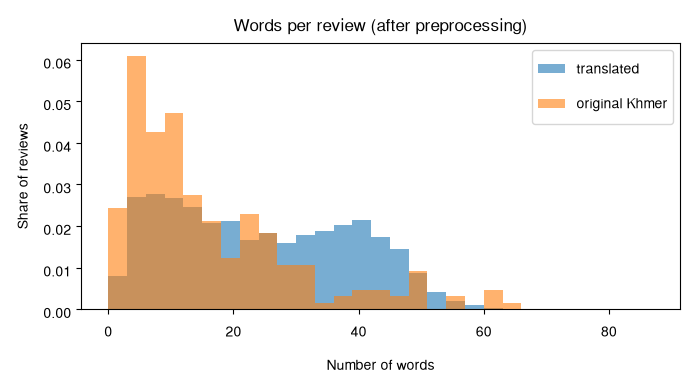

In [18]:
plt.figure(figsize=(7, 4))
for name, n in groups.items():
    plt.hist(n, bins=range(0, 90, 3), alpha=0.6, density=True, label=name)
plt.title("Words per review (after preprocessing)")
plt.xlabel("Number of words")
plt.ylabel("Share of reviews")
plt.legend()
plt.tight_layout()
plt.savefig("results/figures/01_tokens_per_review.png", dpi=150)
plt.show()

#### Maximum length for the BiLSTM

The BiLSTM (notebook 03) needs a fixed input length. We use the 95th percentile of the review length: 95% of the reviews fit completely, longer reviews are cut.

In [19]:
max_len = int(np.ceil(df["n_tokens"].quantile(0.95)))
print("max_len for notebook 03:", max_len)
print(f"Reviews longer than max_len (will be cut): {(df['n_tokens'] > max_len).sum()} ({(df['n_tokens'] > max_len).mean():.1%})")

max_len for notebook 03: 47
Reviews longer than max_len (will be cut): 188 (4.9%)


### 7. Train / Validation / Test Splits

1. **Remove duplicate texts first**, so the same Khmer text can never be in training *and* in a test set.
   (Different English reviews can have the same translation, e.g. *"Very good company"* and *"Great company"* → *"ក្រុមហ៊ុនល្អណាស់។"*)
2. **test_native** = all reviews written in Khmer. They are **never** used for training or tuning.
3. The translated reviews are split **80% / 10% / 10%**, stratified by label (same share of positive/negative in every set), seed 45.

In [20]:
before = len(df)
labels_per_text = df.groupby("text_km")["label"].nunique()
conflicts = labels_per_text[labels_per_text > 1].index
print("Duplicate texts with different labels (removed completely):", len(conflicts))

df = df[~df["text_km"].isin(conflicts)]
df = df.drop_duplicates("text_km", keep="first").reset_index(drop=True)
print(f"Removed {before - len(df)} rows → {len(df)} unique reviews")

Duplicate texts with different labels (removed completely): 0
Removed 73 rows → 3791 unique reviews


#### Splitting

The reviews written in Khmer (pure Khmer + code-switched) become `test_native`. The translated reviews are split 80 / 10 / 10 into train, validation and test_translated, stratified by label (seed 45).

In [21]:
test_native = df[df["language_group"] != "translated"].copy()
translated = df[df["language_group"] == "translated"]

train, temp = train_test_split(translated, test_size=0.2, stratify=translated["label"], random_state=SEED)
val, test_translated = train_test_split(temp, test_size=0.5, stratify=temp["label"], random_state=SEED)

splits = {"train": train, "val": val, "test_translated": test_translated, "test_native": test_native}
used_for = {
    "train": "learn the weights",
    "val": "choose settings and the best epoch",
    "test_translated": "final score on translated Khmer text (used once)",
    "test_native": "final score on real Khmer reviews (used once)",
}
summary = pd.DataFrame({"size": [len(split) for split in splits.values()],
                        "content": ["translated", "translated", "translated", "written in Khmer"],
                        "used for": list(used_for.values())},
                       index=list(splits.keys()))
print(summary.to_string())

                 size           content                                          used for
train            2858        translated                                 learn the weights
val               357        translated                choose settings and the best epoch
test_translated   358        translated  final score on translated Khmer text (used once)
test_native       218  written in Khmer     final score on real Khmer reviews (used once)


#### Labels per split

In [22]:
counts = pd.DataFrame({name: split["label"].value_counts() for name, split in splits.items()}).T[label_names]
counts["% positive"] = (100 * counts["positive"] / counts.sum(axis=1)).round(1)
print(counts)
print("\ntest_native by language group:")
print(test_native["language_group"].value_counts().to_string())

label            negative  positive  % positive
train                1429      1429        50.0
val                   178       179        50.1
test_translated       179       179        50.0
test_native           173        45        20.6

test_native by language group:
language_group
pure_khmer       197
code_switched     21


### 8. Gold Labels for test_native

The labels above are **silver** (AI) labels. For the most important test set, **test_native**, two team members label
every review **independently** in `data/labels/gold_test_annotation_A.csv` and `..._B.csv`.

| Situation | What this cell does |
|---|---|
| both files filled in | Cohen's **kappa** (agreement beyond chance) → saves the disagreements to `gold_disagreements.csv` → we decide those together (`final_label`) → `gold_test_labels.csv` |
| `gold_test_labels.csv` exists | uses the **gold** labels for test_native (drops reviews marked unusable, and neutral ones) |
| files not filled in yet | keeps the **silver** labels and prints a **warning**: test_native results are **provisional** |

In [23]:
LABELS_DIR = "data/labels"
FILE_A = f"{LABELS_DIR}/gold_test_annotation_A.csv"
FILE_B = f"{LABELS_DIR}/gold_test_annotation_B.csv"
FILE_DISAGREE = f"{LABELS_DIR}/gold_disagreements.csv"
FILE_GOLD = f"{LABELS_DIR}/gold_test_labels.csv"

def read_annotation(path):
    ann = pd.read_csv(path, keep_default_na=False, encoding="utf-8-sig")
    ann["label"] = ann["label"].str.strip().str.lower()
    ann["is_usable"] = ann["is_usable"].str.strip().str.lower()
    return ann

def is_filled(ann):
    """Every row has is_usable (yes/no), and every usable row has a valid label."""
    bad_usable = ~ann["is_usable"].isin(["yes", "no"])
    bad_label = (ann["is_usable"] == "yes") & ~ann["label"].isin(["positive", "negative", "neutral"])
    if bad_usable.any() or bad_label.any():
        print(f"  {bad_usable.sum()} rows without yes/no in is_usable, {bad_label.sum()} usable rows without a valid label")
        return False
    return True

def build_gold_labels():
    """Returns a table row_id → gold_label, or None if the gold labels are not ready yet."""
    if os.path.exists(FILE_GOLD):
        return pd.read_csv(FILE_GOLD)

    a, b = read_annotation(FILE_A), read_annotation(FILE_B)
    print(f"Annotation A filled: {(a['is_usable'] != '').sum()}/{len(a)} | B filled: {(b['is_usable'] != '').sum()}/{len(b)}")
    if not (is_filled(a) & is_filled(b)):
        return None

    both = a.merge(b, on="row_id", suffixes=("_A", "_B"))
    usable = both[(both["is_usable_A"] == "yes") & (both["is_usable_B"] == "yes")]
    kappa = cohen_kappa_score(usable["label_A"], usable["label_B"])
    raw = (usable["label_A"] == usable["label_B"]).mean()
    print(f"Reviews both marked usable: {len(usable)} | raw agreement: {raw:.1%} | Cohen's kappa: {kappa:.3f}")

    disagree = usable[usable["label_A"] != usable["label_B"]]
    if len(disagree) > 0 and not os.path.exists(FILE_DISAGREE):
        disagree[["row_id", "text_A", "label_A", "label_B"]].rename(columns={"text_A": "text"}) \
            .assign(final_label="").to_csv(FILE_DISAGREE, index=False, encoding="utf-8-sig")
        print(f"STOP: {len(disagree)} disagreements saved to {FILE_DISAGREE}. Fill in 'final_label' together, then run again.")
        return None
    if len(disagree) > 0:
        decided = pd.read_csv(FILE_DISAGREE, keep_default_na=False, encoding="utf-8-sig")
        if (decided["final_label"].str.strip() == "").any():
            print(f"STOP: some 'final_label' values in {FILE_DISAGREE} are still empty.")
            return None
        final = dict(zip(decided["row_id"], decided["final_label"].str.strip().str.lower()))
    else:
        final = {}

    gold = usable[["row_id", "label_A"]].rename(columns={"label_A": "gold_label"})
    gold["gold_label"] = [final.get(rid, label) for rid, label in zip(gold["row_id"], gold["gold_label"])]
    gold.to_csv(FILE_GOLD, index=False)
    print(f"Saved {len(gold)} gold labels to {FILE_GOLD}")
    return gold

gold = build_gold_labels()

#### Which labels does test_native use?

If the gold (human) labels exist, `test_native` uses them; otherwise it falls back on the silver (AI) labels and all test_native results are provisional. We also check how often the silver labels agree with the gold labels.

In [24]:
if gold is None:
    test_native["label_source"] = "silver"
    print("⚠ WARNING: the gold labels are not ready yet → test_native uses the SILVER (AI) labels.")
    print("  All test_native results in notebooks 02-05 are PROVISIONAL until the gold labels exist.")
else:
    native = test_native.merge(gold, on="row_id", how="inner")
    print(f"Silver vs gold agreement (3 classes): {(native['label'] == native['gold_label']).mean():.1%}")
    print("Gold neutral reviews dropped (2-class project):", (native["gold_label"] == "neutral").sum())
    native = native[native["gold_label"].isin(label_names)].copy()
    native["label"] = native["gold_label"]
    native["label_id"] = native["label"].map(label2id)
    native["label_source"] = "gold"
    test_native = native.drop(columns="gold_label")
    print("test_native with gold labels:", len(test_native))

for name in ["train", "val", "test_translated"]:
    splits[name] = splits[name].assign(label_source="silver")
splits["test_native"] = test_native
print("test_native label source:", test_native["label_source"].iloc[0], "|", len(test_native), "reviews")

Silver vs gold agreement (3 classes): 98.2%
Gold neutral reviews dropped (2-class project): 3
test_native with gold labels: 214
test_native label source: gold | 214 reviews


### 9. Save

One CSV per split in `data/processed/`. The tokens are saved as **one string with spaces between the words**
(so `"អ្នកបើកបរ មិន សូវ"` → `.split()` gives the list back). `settings.json` keeps the shared settings for notebooks 02–05.

In [25]:
columns = ["row_id", "text", "text_km", "tokens", "label", "label_id", "language_group",
           "label_source", "translation_issue", "score"]

for name, split in splits.items():
    out = split.copy()
    out["tokens"] = out["tokens"].apply(" ".join)
    out[columns].to_csv(f"data/processed/{name}.csv", index=False, encoding="utf-8")
    print(f"data/processed/{name}.csv: {len(out)} rows")

settings = {
    "seed": SEED,
    "label_names": label_names,
    "max_len": max_len,
    "test_native_label_source": splits["test_native"]["label_source"].iloc[0],
}
with open("data/processed/settings.json", "w") as f:
    json.dump(settings, f, indent=2)
print("\nsettings.json:", settings)

data/processed/train.csv: 2858 rows
data/processed/val.csv: 357 rows
data/processed/test_translated.csv: 358 rows
data/processed/test_native.csv: 214 rows

settings.json: {'seed': 45, 'label_names': ['negative', 'positive'], 'max_len': 47, 'test_native_label_source': 'gold'}


#### Check

We load one saved file back to make sure the tokens can be read again.

In [26]:
# Check: load one file back
check = pd.read_csv("data/processed/train.csv")
print(check.shape)
print("tokens as a list again:", check["tokens"].iloc[0].split()[:10])

(2858, 10)
tokens as a list again: ['គេហទំព័រ', 'ត្រូវ', 'ធ្វើ', 'បច្ចុប្បន្នភាព', 'កន្លែង', 'ឡើង', 'ឡាន', 'បាន', 'ផ្លាស់ទី', 'ហើយ']


### 10. Observations

- **From 4,114 rows to 3,791 reviews**: 16 rows excluded (no usable text) → 234 neutral reviews removed (2 classes) →
  73 duplicate Khmer texts removed (no duplicate had two different labels).
- **The score is not a good label**: only 62.3% of score-based labels agree with what the reviews say.
- **Splits**: train 2,858 · validation 357 · test_translated 358 · test_native 214 (193 pure Khmer, 21 code-switched).
- **Gold labels for test_native**: two team members labeled the 228 Khmer reviews independently. They agreed on **96.4%**
  of the 222 reviews both marked usable (**Cohen's kappa 0.902**, "almost perfect"); the 8 disagreements were decided together.
  The silver (AI) labels agree with the gold labels on **98.2%** of these reviews. With the gold labels, test_native has
  **214 reviews** (4 fewer than with silver labels: 3 judged neutral by the annotators, 1 marked unusable).
- **The translated sets are balanced** (about 50% positive), but **test_native is only 20.6% positive** (44 of 214): the
  reviews written in Khmer are mostly complaints. A model that always says "negative" would already get 79% accuracy on
  test_native, so **macro-F1** (the average F1 of both classes) is our main metric.
- **Khmer reviews are shorter** (median 11 words vs. 22 for translations), but the 95th percentile is almost the same
  (48 vs. 47) → `max_len = 47`, only 4.9% of reviews are cut.
- **Negation is kept**: មិន appears in 1,471 reviews, ទេ in 585, គ្មាន in 568.
- Only **21 code-switched** reviews: the pure-Khmer vs. code-switched comparison in the next notebooks will be very uncertain.